In [1]:
!pip install SimpleITK pydicom pandas numpy scikit-image --quiet

## Step 1: Preprocessing pipeline for CT nodule data (LUNA16)
Task = LUNA16 false-positive reduction: label 1 = candidate is a real nodule, 0 = not a nodule (NOT malignancy).
Each candidate becomes a 2.5D patch: axial / coronal / sagittal planes through the candidate centre, stacked as
3 channels (Roth et al. 2014; Setio et al. 2016 used 50 mm patches at 64 px).

In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import SimpleITK as sitk
from pathlib import Path


def find_file(name, search_dir="/kaggle/input"):
   for root, dirs, files in os.walk(search_dir):
       if name in files:
           return os.path.join(root, name)
   return None


# candidates_V2.csv is the version recommended by the LUNA16 organisers; fall back to V1 if the mirror lacks it.
CANDIDATES_CSV = find_file("candidates_V2.csv") or find_file("candidates.csv")
if CANDIDATES_CSV is None:
   raise FileNotFoundError("No candidates(_V2).csv under /kaggle/input. Check that the LUNA16 dataset is attached.")
NODULE_ANNOTATIONS_CSV = find_file("annotations.csv")     # nodule centres + diameters (used for EDA only)
RAW_DATA_DIR = "/kaggle/input"                             # .mhd files may sit outside the CSV folder
print(f"Candidates file: {CANDIDATES_CSV}")


OUTPUT_DIR = "/kaggle/working/preprocessed"
CROP_SIZE = 64             # pixels per side
CROP_MM = 50.0             # physical side length of the patch (Setio et al. 2016)
HU_MIN, HU_MAX = -1000, 400
NEGATIVE_TO_POSITIVE_RATIO = 3
RANDOM_SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

def load_ct_volume(mhd_path):
   """Load a .mhd/.raw CT scan, clip to the lung window and scale to [0, 1].
   Kept as a SimpleITK image so origin, spacing and direction stay attached to the voxels."""
   img = sitk.ReadImage(mhd_path, sitk.sitkFloat32)
   img = sitk.Clamp(img, sitk.sitkFloat32, HU_MIN, HU_MAX)
   return (img - HU_MIN) / (HU_MAX - HU_MIN)

def extract_25d_crop(img, world_xyz, crop_size=CROP_SIZE, crop_mm=CROP_MM):
   """Resample an isotropic cube of crop_mm around the candidate (world mm coordinates) and return its three
   central orthogonal planes (axial, coronal, sagittal) as a (3, crop_size, crop_size) array.
   Resampling to a fixed mm grid removes the scanner-dependent pixel spacing / slice thickness."""
   sp = crop_mm / crop_size
   D = np.array(img.GetDirection()).reshape(3, 3)
   ref = sitk.Image(crop_size, crop_size, crop_size, sitk.sitkFloat32)
   ref.SetSpacing((sp, sp, sp))
   ref.SetDirection(img.GetDirection())
   ref.SetOrigin(tuple(float(v) for v in np.asarray(world_xyz) - D @ np.full(3, sp * (crop_size - 1) / 2.0)))
   # outside the scan -> 0 (= -1000 HU, air)
   cube = sitk.GetArrayFromImage(sitk.Resample(img, ref, sitk.Transform(), sitk.sitkLinear, 0.0))  # z, y, x
   c = crop_size // 2
   return np.stack([cube[c], cube[:, c, :], cube[:, :, c]]).astype(np.float32)


def main():
   annotations = pd.read_csv(CANDIDATES_CSV)
   print(f"Loaded {len(annotations)} total candidates")

   # one path per series (some Kaggle mirrors contain duplicated subset folders)
   mhd_files = {p.stem: p for p in Path(RAW_DATA_DIR).rglob("*.mhd")}
   print(f"Found {len(mhd_files)} CT series")
   annotations = annotations[annotations["seriesuid"].isin(mhd_files)]
   print(annotations["class"].value_counts(), "\n(class balance before subsampling, available scans only)")

   # Balance: keep all positives, subsample negatives
   positives = annotations[annotations["class"] == 1]
   negatives = annotations[annotations["class"] == 0]
   n_negatives_to_keep = min(len(negatives), len(positives) * NEGATIVE_TO_POSITIVE_RATIO)
   negatives_sampled = negatives.sample(n=n_negatives_to_keep, random_state=RANDOM_SEED)
   annotations = pd.concat([positives, negatives_sampled]).sample(frac=1, random_state=RANDOM_SEED)
   print(f"After subsampling: {len(positives)} positive, {len(negatives_sampled)} negative "
         f"({len(annotations)} total candidates to process)")

   records = []
   for series_uid, series_annotations in annotations.groupby("seriesuid"):
       img = load_ct_volume(str(mhd_files[series_uid]))

       for idx, row in series_annotations.iterrows():
           crop = extract_25d_crop(img, (row["coordX"], row["coordY"], row["coordZ"]))

           out_name = f"{series_uid}_{idx}.npy"
           np.save(os.path.join(OUTPUT_DIR, out_name), crop)

           records.append({
               "filename": out_name,
               "series_uid": series_uid,
               "label": int(row["class"]),
           })

   labels_df = pd.DataFrame(records)
   labels_df.to_csv(os.path.join(OUTPUT_DIR, "labels.csv"), index=False)
   if NODULE_ANNOTATIONS_CSV:
       shutil.copy(NODULE_ANNOTATIONS_CSV, os.path.join(OUTPUT_DIR, "nodule_annotations.csv"))
   print(f"Saved {len(labels_df)} preprocessed crops to {OUTPUT_DIR}")
   if len(labels_df) > 0 and "label" in labels_df.columns:
       print(labels_df["label"].value_counts())
   else:
       print("WARNING: no crops were produced. 0 matching CT series means the .mhd files were not found "
             "under /kaggle/input or their names do not match candidates seriesuid.")


if __name__ == "__main__":
   main()

Candidates file: /kaggle/input/datasets/avc0706/luna16/candidates_V2/candidates_V2.csv
Loaded 754975 total candidates
Found 888 CT series
class
0    753418
1      1557
Name: count, dtype: int64 
(class balance before subsampling, available scans only)
After subsampling: 1557 positive, 4671 negative (6228 total candidates to process)
Saved 6228 preprocessed crops to /kaggle/working/preprocessed
label
0    4671
1    1557
Name: count, dtype: int64


## Step 2: Patient-level train/val/test split.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

LABELS_CSV = "/kaggle/working/preprocessed/labels.csv"
OUTPUT_DIR = "/kaggle/working/preprocessed"

RANDOM_SEED = 42
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15


def main():
   df = pd.read_csv(LABELS_CSV)


   unique_patients = df["series_uid"].unique()
   print(f"Total unique patients/series: {len(unique_patients)}")


   train_patients, temp_patients = train_test_split(
       unique_patients, train_size=TRAIN_FRAC, random_state=RANDOM_SEED
   )
   val_size_relative = VAL_FRAC / (1 - TRAIN_FRAC)
   val_patients, test_patients = train_test_split(
       temp_patients, train_size=val_size_relative, random_state=RANDOM_SEED
   )


   df["split"] = "test"
   df.loc[df["series_uid"].isin(train_patients), "split"] = "train"
   df.loc[df["series_uid"].isin(val_patients), "split"] = "val"


   # sanity check: no patient overlap across splits
   train_set = set(df[df["split"] == "train"]["series_uid"])
   val_set = set(df[df["split"] == "val"]["series_uid"])
   test_set = set(df[df["split"] == "test"]["series_uid"])
   assert not (train_set & val_set), "Patient leakage between train/val!"
   assert not (train_set & test_set), "Patient leakage between train/test!"
   assert not (val_set & test_set), "Patient leakage between val/test!"
   print("No patient leakage across splits - confirmed.")


   print(df.groupby("split")["label"].agg(crops="count", positives="sum"))
   df.to_csv(f"{OUTPUT_DIR}/labels_split.csv", index=False)
   print(f"Saved split file to {OUTPUT_DIR}/labels_split.csv")



if __name__ == "__main__":
   main()

Total unique patients/series: 876
No patient leakage across splits - confirmed.
       crops  positives
split                  
test    1039        260
train   4263       1072
val      926        225
Saved split file to /kaggle/working/preprocessed/labels_split.csv


## Step 3: Exploratory Data Analysis

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "/kaggle/working/preprocessed"
LABELS_CSV = f"{DATA_DIR}/labels_split.csv"
FIG_DIR = "/kaggle/working/figures/eda"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_style("whitegrid")


def main():
   df = pd.read_csv(LABELS_CSV)
   print(f"Total crops: {len(df)}")
   print(f"Unique patients/series: {df['series_uid'].nunique()}")
   print(df.groupby("split")["series_uid"].nunique(), "\n(patients per split)")


   # 1. Class balance overall and per split
   fig, axes = plt.subplots(1, 2, figsize=(12, 4))
   df["label"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
   axes[0].set_title("Overall class balance")
   axes[0].set_xlabel("Label (0=non-nodule candidate, 1=nodule)")
   axes[0].set_ylabel("Count")


   split_counts = df.groupby(["split", "label"]).size().unstack(fill_value=0)
   split_counts.plot(kind="bar", stacked=True, ax=axes[1])
   axes[1].set_title("Class balance per split")
   axes[1].set_xlabel("Split")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/class_balance.png", dpi=150)
   plt.close()


   # 2. Nodule diameter distribution (from annotations.csv; candidates have no diameter)
   nodules_csv = f"{DATA_DIR}/nodule_annotations.csv"
   if os.path.exists(nodules_csv):
       nodules = pd.read_csv(nodules_csv)
       nodules = nodules[nodules["seriesuid"].isin(df["series_uid"])]
       plt.figure(figsize=(7, 4))
       sns.histplot(nodules["diameter_mm"], bins=30, kde=True, color="#4C72B0")
       plt.title("Nodule diameter distribution (mm)")
       plt.xlabel("Diameter (mm)")
       plt.tight_layout()
       plt.savefig(f"{FIG_DIR}/diameter_distribution.png", dpi=150)
       plt.close()


   # 3. Sample crop grid (mix of both classes; axial channel shown)
   fig, axes = plt.subplots(2, 5, figsize=(15, 6))
   for label_val, row_idx in [(0, 0), (1, 1)]:
       subset = df[df["label"] == label_val].sample(min(5, (df["label"] == label_val).sum()), random_state=42)
       for col_idx, (_, row) in enumerate(subset.iterrows()):
           crop = np.load(os.path.join(DATA_DIR, row["filename"]))
           axes[row_idx, col_idx].imshow(crop[0], cmap="gray", vmin=0, vmax=1)
           axes[row_idx, col_idx].set_title(f"label={label_val}", fontsize=9)
           axes[row_idx, col_idx].axis("off")
   plt.suptitle("Sample nodule crops by class")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/sample_crops.png", dpi=150)
   plt.close()


   # 3b. One nodule shown as the three input channels (illustrates the 2.5D representation)
   crop = np.load(os.path.join(DATA_DIR, df[df["label"] == 1].sample(1, random_state=42)["filename"].iloc[0]))
   fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
   for ax, view, title in zip(axes, crop, ["Axial (ch 0)", "Coronal (ch 1)", "Sagittal (ch 2)"]):
       ax.imshow(view, cmap="gray", vmin=0, vmax=1)
       ax.set_title(title, fontsize=10)
       ax.axis("off")
   plt.suptitle("2.5D input: three orthogonal 50 mm views of one nodule")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/views_example.png", dpi=150)
   plt.close()


   # 4. Pixel intensity histogram (sanity check on normalization)
   sample_files = df["filename"].sample(min(200, len(df)), random_state=42)
   all_pixels = np.concatenate([
       np.load(os.path.join(DATA_DIR, f)).ravel() for f in sample_files
   ])
   plt.figure(figsize=(7, 4))
   sns.histplot(all_pixels, bins=50, color="#55A868")
   plt.title("Pixel intensity distribution (post lung-window normalization)")
   plt.xlabel("Normalized intensity [0,1]")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/pixel_intensity_hist.png", dpi=150)
   plt.close()

   print(f"\nAll EDA figures saved to {FIG_DIR}")


if __name__ == "__main__":
   main()

Total crops: 6228
Unique patients/series: 876
split
test     132
train    613
val      131
Name: series_uid, dtype: int64 
(patients per split)

All EDA figures saved to /kaggle/working/figures/eda


In [11]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
   accuracy_score, precision_score, recall_score, f1_score,
   roc_auc_score, average_precision_score, confusion_matrix,
   roc_curve, precision_recall_curve, brier_score_loss,
)
from sklearn.calibration import calibration_curve


sns.set_style("whitegrid")

DATA_DIR = "/kaggle/working/preprocessed"
LABELS_CSV = f"{DATA_DIR}/labels_split.csv"
OUT_DIR = "/kaggle/working/model_results"
FIG_DIR = "/kaggle/working/figures/per_model"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


BATCH_SIZE = 32
NUM_EPOCHS = 25
LEARNING_RATE = 1e-4
INPUT_SIZE = 224            # ImageNet backbones are built for 224 px; 64 px leaves only a 2x2 final feature map
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)


# applied to every split, after augmentation: upsample + ImageNet normalisation (matches pretraining)
to_model_input = transforms.Compose([
   transforms.Resize((INPUT_SIZE, INPUT_SIZE), antialias=True),
   transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def expected_calibration_error(y, p, n_bins=10):
   """ECE (Guo et al. 2017): bin-size-weighted gap between mean confidence and observed positive rate."""
   y, p = np.asarray(y), np.asarray(p)
   bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
   return float(sum(abs(y[bins == b].mean() - p[bins == b].mean()) * (bins == b).mean()
                    for b in range(n_bins) if (bins == b).any()))


class NoduleDataset(Dataset):
   def __init__(self, df, data_dir, transform=None):
       self.df = df.reset_index(drop=True)
       self.data_dir = data_dir
       self.transform = transform


   def __len__(self):
       return len(self.df)

   def __getitem__(self, idx):
       row = self.df.iloc[idx]
       crop = np.load(os.path.join(self.data_dir, row["filename"]))   # (3, H, W): axial, coronal, sagittal
       crop_tensor = torch.from_numpy(crop).float()
       if self.transform:
           crop_tensor = self.transform(crop_tensor)
       return crop_tensor, int(row["label"]), row["filename"]


def build_model(name):
   if name == "resnet50":
       m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
       m.fc = nn.Linear(m.fc.in_features, 2)
   elif name == "densenet121":
       m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
       m.classifier = nn.Linear(m.classifier.in_features, 2)
   elif name == "efficientnet_b0":
       m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
       m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
   elif name == "vgg16_bn":
       m = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)
       m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2)
   else:
       raise ValueError(f"Unknown model name: {name}")
   return m.to(DEVICE)


# Train / eval loops
def train_one_epoch(model, loader, optimizer, criterion):
   model.train()
   running_loss, correct, total = 0.0, 0, 0
   for images, labels, _ in loader:
       images, labels = images.to(DEVICE), labels.to(DEVICE)
       optimizer.zero_grad()
       outputs = model(images)
       loss = criterion(outputs, labels)
       loss.backward()
       optimizer.step()
       running_loss += loss.item() * images.size(0)
       correct += (outputs.argmax(1) == labels).sum().item()
       total += images.size(0)
   return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, return_predictions=False):
   model.eval()
   all_labels, all_preds, all_probs, all_files = [], [], [], []
   running_loss, criterion = 0.0, nn.CrossEntropyLoss()


   for images, labels, filenames in loader:
       images_dev, labels_dev = images.to(DEVICE), labels.to(DEVICE)
       outputs = model(images_dev)
       loss = criterion(outputs, labels_dev)
       running_loss += loss.item() * images.size(0)


       probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
       preds = outputs.argmax(dim=1).cpu().numpy()


       all_labels.extend(labels.numpy())
       all_preds.extend(preds)
       all_probs.extend(probs)
       all_files.extend(filenames)


   metrics = {
       "loss": running_loss / len(loader.dataset),
       "accuracy": accuracy_score(all_labels, all_preds),
       "precision": precision_score(all_labels, all_preds, zero_division=0),
       "recall_sensitivity": recall_score(all_labels, all_preds, zero_division=0),
       "f1": f1_score(all_labels, all_preds, zero_division=0),
       "roc_auc": roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float("nan"),
       "pr_auc": average_precision_score(all_labels, all_probs),
       "brier": brier_score_loss(all_labels, all_probs),
       "ece": expected_calibration_error(all_labels, all_probs),
   }
   tn, fp, fn, tp = confusion_matrix(all_labels, all_preds, labels=[0, 1]).ravel()
   metrics["specificity"] = tn / (tn + fp) if (tn + fp) > 0 else 0.0


   if return_predictions:
       pred_df = pd.DataFrame({
           "filename": all_files, "label": all_labels,
           "pred": all_preds, "prob": all_probs,
       })
       return metrics, pred_df
   return metrics


# Full train-one-model
def train_model(model_name, train_loader, val_loader, test_loader, num_epochs=NUM_EPOCHS):
   print(f"\n{'='*60}\nTraining {model_name} ({num_epochs} epochs)\n{'='*60}")
   model = build_model(model_name)
   criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)   # 1:3 imbalance -> keep sensitivity at threshold 0.5
   optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
   scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3)


   history = []
   best_val_auc = 0.0
   checkpoint_path = f"{OUT_DIR}/{model_name}_best.pt"


   for epoch in range(num_epochs):
       start = time.time()
       train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
       val_metrics = evaluate(model, val_loader)
       scheduler.step(val_metrics["roc_auc"])
       elapsed = time.time() - start


       history.append({
           "epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
           "val_loss": val_metrics["loss"], "val_acc": val_metrics["accuracy"],
           "val_roc_auc": val_metrics["roc_auc"], "val_pr_auc": val_metrics["pr_auc"],
           "val_sensitivity": val_metrics["recall_sensitivity"], "val_specificity": val_metrics["specificity"],
       })
       print(f"[{model_name}] epoch {epoch+1}/{num_epochs} "
             f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
             f"val_acc={val_metrics['accuracy']:.4f} val_auc={val_metrics['roc_auc']:.4f} ({elapsed:.1f}s)")


       if val_metrics["roc_auc"] > best_val_auc:
           best_val_auc = val_metrics["roc_auc"]
           torch.save(model.state_dict(), checkpoint_path)


   history_df = pd.DataFrame(history)
   history_df.to_csv(f"{OUT_DIR}/{model_name}_history.csv", index=False)


   model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
   test_metrics, test_pred_df = evaluate(model, test_loader, return_predictions=True)
   test_pred_df.to_csv(f"{OUT_DIR}/{model_name}_test_predictions.csv", index=False)
   pd.DataFrame([test_metrics]).to_csv(f"{OUT_DIR}/{model_name}_test_metrics.csv", index=False)


   print(f"\n[{model_name}] FINAL TEST METRICS:")
   for k, v in test_metrics.items():
       print(f"  {k}: {v:.4f}")

   return model, history_df, test_metrics, test_pred_df


# Per-model plotting: train vs val curves, ROC, PR, confusion matrix
def plot_model_report(model_name, history_df, test_metrics, test_pred_df):
   fig, axes = plt.subplots(2, 3, figsize=(16, 9))

   # 1. Train vs Val loss
   axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="train")
   axes[0, 0].plot(history_df["epoch"], history_df["val_loss"], label="val")
   axes[0, 0].set_title(f"{model_name} - Loss")
   axes[0, 0].set_xlabel("Epoch")
   axes[0, 0].legend()

   # 2. Train vs Val accuracy
   axes[0, 1].plot(history_df["epoch"], history_df["train_acc"], label="train")
   axes[0, 1].plot(history_df["epoch"], history_df["val_acc"], label="val")
   axes[0, 1].set_title(f"{model_name} - Accuracy")
   axes[0, 1].set_xlabel("Epoch")
   axes[0, 1].legend()

   # 3. Val ROC-AUC / PR-AUC across epochs
   axes[0, 2].plot(history_df["epoch"], history_df["val_roc_auc"], label="val ROC-AUC")
   axes[0, 2].plot(history_df["epoch"], history_df["val_pr_auc"], label="val PR-AUC")
   axes[0, 2].set_title(f"{model_name} - Val ROC-AUC / PR-AUC")
   axes[0, 2].set_xlabel("Epoch")
   axes[0, 2].legend()

   # 4. ROC curve (final test set)
   fpr, tpr, _ = roc_curve(test_pred_df["label"], test_pred_df["prob"])
   axes[1, 0].plot(fpr, tpr, label=f"AUC={test_metrics['roc_auc']:.3f}")
   axes[1, 0].plot([0, 1], [0, 1], "k:", alpha=0.5)
   axes[1, 0].set_title(f"{model_name} - ROC curve (test)")
   axes[1, 0].set_xlabel("False Positive Rate")
   axes[1, 0].set_ylabel("True Positive Rate")
   axes[1, 0].legend()

   # 5. Precision-Recall curve (final test set)
   precision, recall, _ = precision_recall_curve(test_pred_df["label"], test_pred_df["prob"])
   axes[1, 1].plot(recall, precision, label=f"AP={test_metrics['pr_auc']:.3f}")
   axes[1, 1].set_title(f"{model_name} - PR curve (test)")
   axes[1, 1].set_xlabel("Recall")
   axes[1, 1].set_ylabel("Precision")
   axes[1, 1].legend()

   # 6. Confusion matrix (final test set)
   cm = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])
   sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1, 2], cbar=False)
   axes[1, 2].set_title(f"{model_name} - Confusion Matrix (test)")
   axes[1, 2].set_xlabel("Predicted")
   axes[1, 2].set_ylabel("Actual")

   plt.tight_layout()
   save_path = f"{FIG_DIR}/{model_name}_full_report.png"
   plt.savefig(save_path, dpi=150)
   plt.show()
   print(f"Saved {save_path}")

   # Print a clean metrics table too
   metrics_table = pd.DataFrame([test_metrics]).T.rename(columns={0: model_name})
   print(f"\n{model_name} test metrics:")
   print(metrics_table.round(4))


df = pd.read_csv(LABELS_CSV)
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]
print(f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")


n_pos = int(train_df["label"].sum())
n_neg = len(train_df) - n_pos
CLASS_WEIGHTS = torch.tensor([len(train_df) / (2 * n_neg), len(train_df) / (2 * n_pos)],
                            dtype=torch.float32, device=DEVICE)
print(f"Class weights (neg, pos): {CLASS_WEIGHTS.tolist()}")


train_transform = transforms.Compose([
   transforms.RandomHorizontalFlip(p=0.5),
   transforms.RandomVerticalFlip(p=0.5),
   transforms.RandomRotation(degrees=15),   # empty corners filled with 0 = air
   to_model_input,
])


train_loader = DataLoader(NoduleDataset(train_df, DATA_DIR, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(NoduleDataset(val_df, DATA_DIR, to_model_input),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(NoduleDataset(test_df, DATA_DIR, to_model_input),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


print("Setup complete. Loaders ready. Proceed to the per-model training blocks.")

Using device: cuda
train=4263, val=926, test=1039
Class weights (neg, pos): [0.6679724454879761, 1.9883395433425903]
Setup complete. Loaders ready. Proceed to the per-model training blocks.


## Train ResNet50


Training resnet50 (25 epochs)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 181MB/s] 


[resnet50] epoch 1/25 train_loss=0.6782 train_acc=0.5970 val_acc=0.7365 val_auc=0.5222 (47.7s)
[resnet50] epoch 2/25 train_loss=0.6651 train_acc=0.6331 val_acc=0.6058 val_auc=0.6174 (46.2s)
[resnet50] epoch 3/25 train_loss=0.6482 train_acc=0.6137 val_acc=0.6015 val_auc=0.5319 (45.6s)
[resnet50] epoch 4/25 train_loss=0.6371 train_acc=0.6355 val_acc=0.5821 val_auc=0.6154 (45.9s)
[resnet50] epoch 5/25 train_loss=0.6227 train_acc=0.6183 val_acc=0.6458 val_auc=0.6252 (45.7s)
[resnet50] epoch 6/25 train_loss=0.6065 train_acc=0.6662 val_acc=0.6674 val_auc=0.6356 (45.6s)
[resnet50] epoch 7/25 train_loss=0.6054 train_acc=0.6486 val_acc=0.6965 val_auc=0.6232 (45.8s)
[resnet50] epoch 8/25 train_loss=0.5977 train_acc=0.6547 val_acc=0.5572 val_auc=0.6001 (45.6s)
[resnet50] epoch 9/25 train_loss=0.5868 train_acc=0.6594 val_acc=0.6080 val_auc=0.5788 (45.5s)
[resnet50] epoch 10/25 train_loss=0.5838 train_acc=0.6721 val_acc=0.5410 val_auc=0.6463 (45.8s)
[resnet50] epoch 11/25 train_loss=0.5861 train_ac

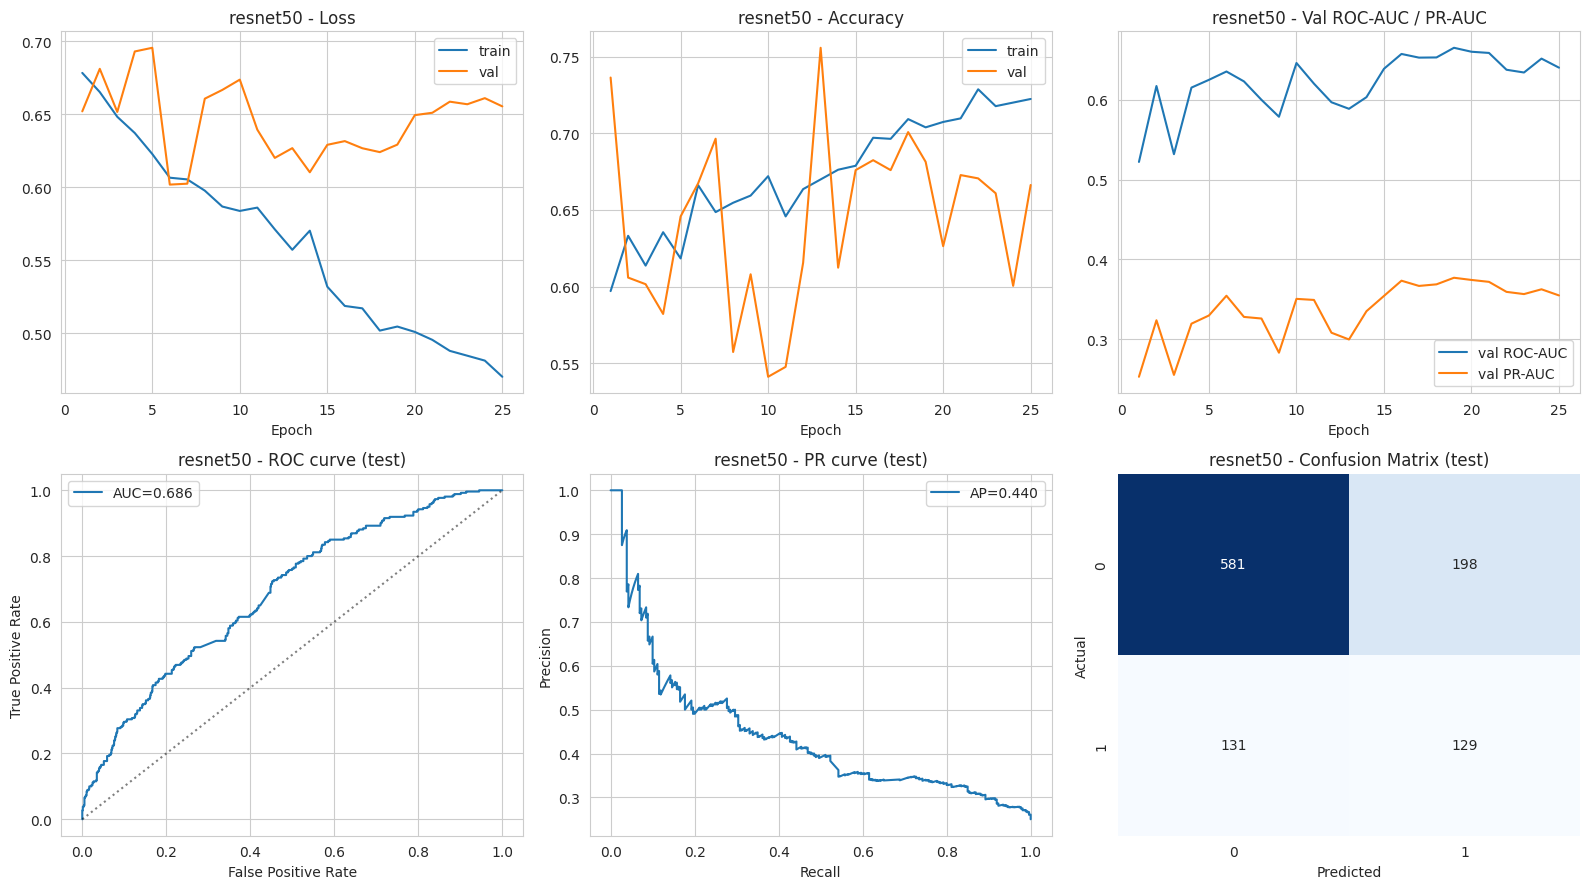

Saved /kaggle/working/figures/per_model/resnet50_full_report.png

resnet50 test metrics:
                    resnet50
loss                  0.6142
accuracy              0.6833
precision             0.3945
recall_sensitivity    0.4962
f1                    0.4395
roc_auc               0.6860
pr_auc                0.4401
brier                 0.2095
ece                   0.1755
specificity           0.7458


In [12]:
resnet50_model, resnet50_history, resnet50_test_metrics, resnet50_test_preds = train_model(
   "resnet50", train_loader, val_loader, test_loader
)

plot_model_report("resnet50", resnet50_history, resnet50_test_metrics, resnet50_test_preds)

## Train DenseNet121


Training densenet121 (25 epochs)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 174MB/s] 


[densenet121] epoch 1/25 train_loss=0.6978 train_acc=0.5599 val_acc=0.7527 val_auc=0.6025 (46.5s)
[densenet121] epoch 2/25 train_loss=0.6757 train_acc=0.5822 val_acc=0.7419 val_auc=0.5239 (46.0s)
[densenet121] epoch 3/25 train_loss=0.6577 train_acc=0.5961 val_acc=0.7484 val_auc=0.6774 (46.1s)
[densenet121] epoch 4/25 train_loss=0.6404 train_acc=0.6183 val_acc=0.7495 val_auc=0.6122 (46.2s)
[densenet121] epoch 5/25 train_loss=0.6253 train_acc=0.6144 val_acc=0.6987 val_auc=0.6326 (46.1s)
[densenet121] epoch 6/25 train_loss=0.6239 train_acc=0.6244 val_acc=0.5086 val_auc=0.6670 (46.1s)
[densenet121] epoch 7/25 train_loss=0.6142 train_acc=0.6343 val_acc=0.6598 val_auc=0.6489 (46.1s)
[densenet121] epoch 8/25 train_loss=0.5830 train_acc=0.6812 val_acc=0.6555 val_auc=0.6738 (46.1s)
[densenet121] epoch 9/25 train_loss=0.5686 train_acc=0.6730 val_acc=0.6641 val_auc=0.6859 (46.2s)
[densenet121] epoch 10/25 train_loss=0.5639 train_acc=0.6578 val_acc=0.6641 val_auc=0.6575 (46.2s)
[densenet121] epoch

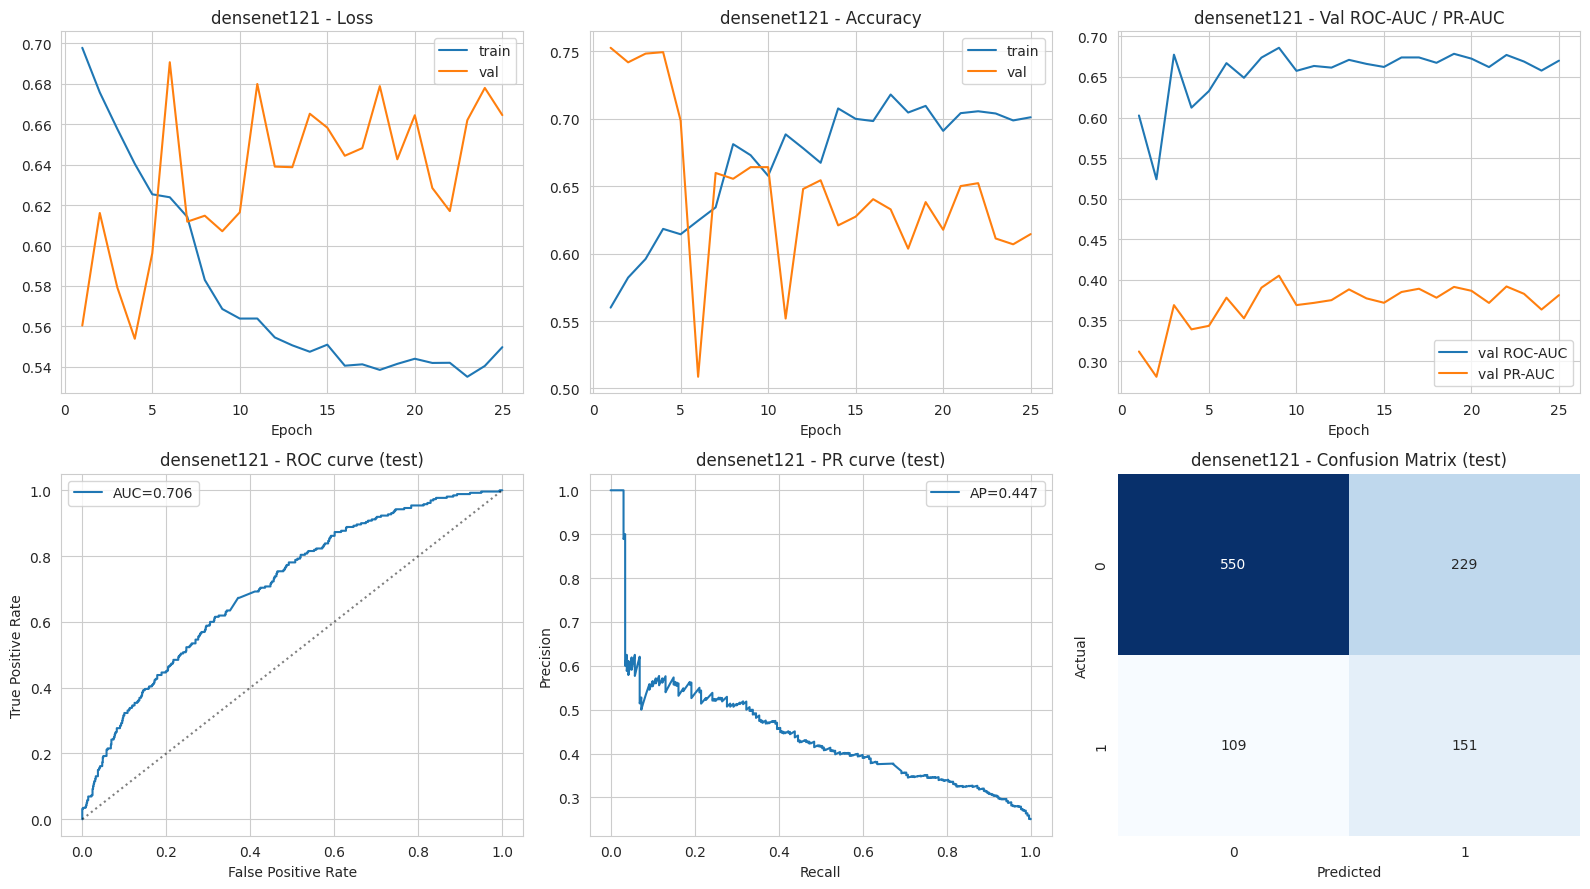

Saved /kaggle/working/figures/per_model/densenet121_full_report.png

densenet121 test metrics:
                    densenet121
loss                     0.5960
accuracy                 0.6747
precision                0.3974
recall_sensitivity       0.5808
f1                       0.4719
roc_auc                  0.7062
pr_auc                   0.4469
brier                    0.2062
ece                      0.1728
specificity              0.7060


In [13]:
densenet121_model, densenet121_history, densenet121_test_metrics, densenet121_test_preds = train_model(
   "densenet121", train_loader, val_loader, test_loader
)

plot_model_report("densenet121", densenet121_history, densenet121_test_metrics, densenet121_test_preds)

## Train EfficientNet-B0


Training efficientnet_b0 (25 epochs)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


[efficientnet_b0] epoch 1/25 train_loss=0.6835 train_acc=0.5644 val_acc=0.7549 val_auc=0.6373 (23.5s)
[efficientnet_b0] epoch 2/25 train_loss=0.6574 train_acc=0.6179 val_acc=0.4741 val_auc=0.6220 (23.1s)
[efficientnet_b0] epoch 3/25 train_loss=0.6430 train_acc=0.6334 val_acc=0.6069 val_auc=0.6283 (23.0s)
[efficientnet_b0] epoch 4/25 train_loss=0.6250 train_acc=0.6404 val_acc=0.3801 val_auc=0.6177 (23.0s)
[efficientnet_b0] epoch 5/25 train_loss=0.6157 train_acc=0.6186 val_acc=0.3790 val_auc=0.5944 (23.1s)
[efficientnet_b0] epoch 6/25 train_loss=0.5964 train_acc=0.6385 val_acc=0.3315 val_auc=0.6011 (23.1s)
[efficientnet_b0] epoch 7/25 train_loss=0.5853 train_acc=0.6348 val_acc=0.4514 val_auc=0.6482 (23.1s)
[efficientnet_b0] epoch 8/25 train_loss=0.5855 train_acc=0.6491 val_acc=0.3855 val_auc=0.6055 (23.2s)
[efficientnet_b0] epoch 9/25 train_loss=0.5896 train_acc=0.6493 val_acc=0.5076 val_auc=0.6724 (23.1s)
[efficientnet_b0] epoch 10/25 train_loss=0.5816 train_acc=0.6446 val_acc=0.3542 va

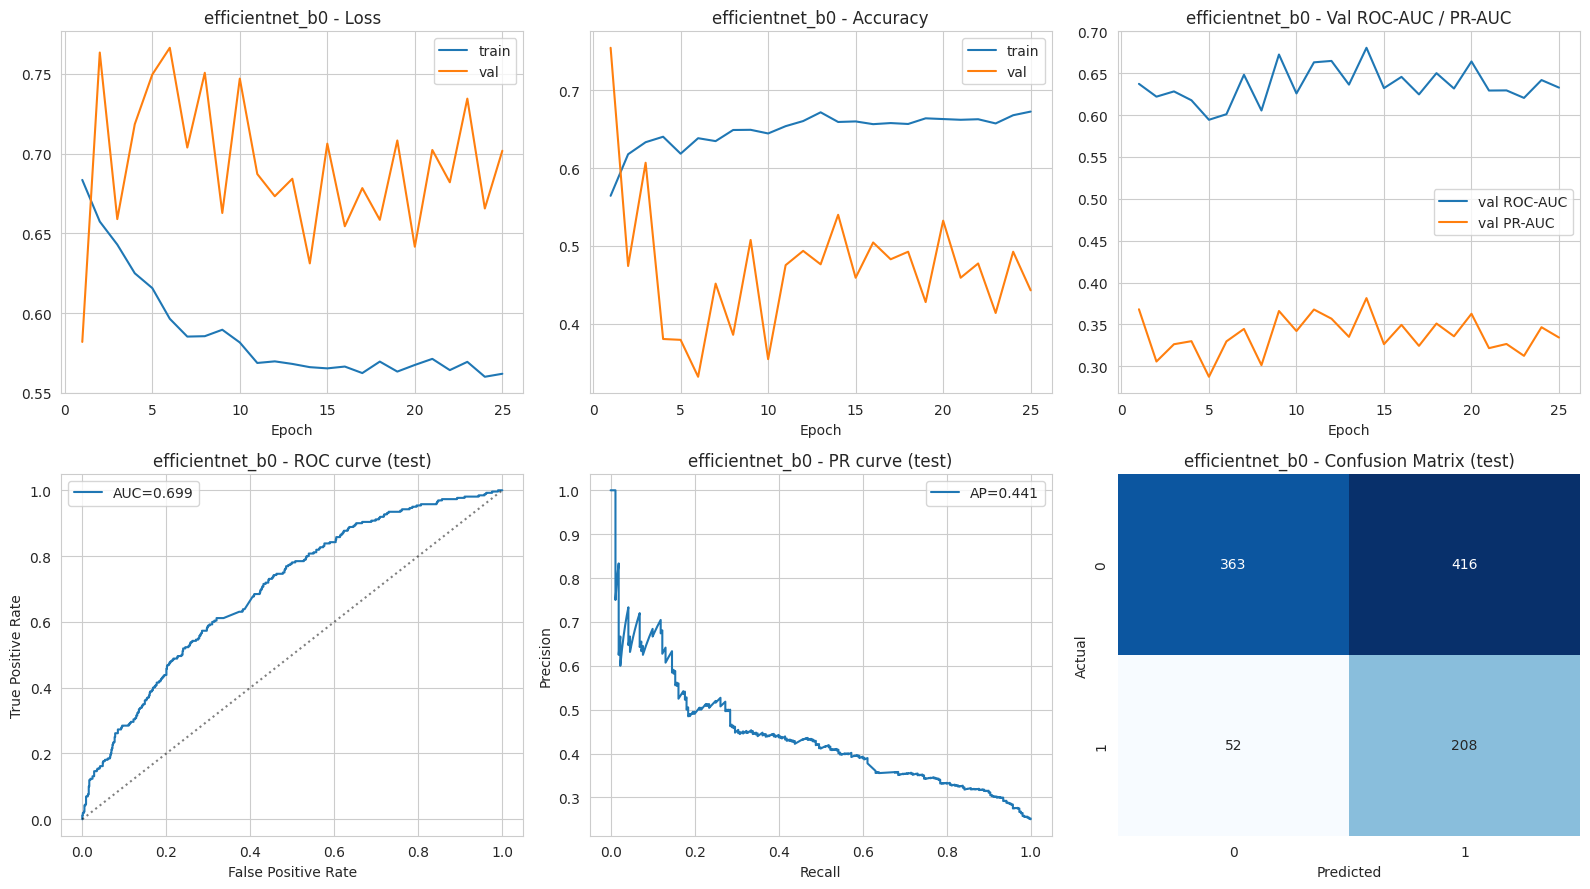

Saved /kaggle/working/figures/per_model/efficientnet_b0_full_report.png

efficientnet_b0 test metrics:
                    efficientnet_b0
loss                         0.6314
accuracy                     0.5496
precision                    0.3333
recall_sensitivity           0.8000
f1                           0.4706
roc_auc                      0.6987
pr_auc                       0.4412
brier                        0.2230
ece                          0.2223
specificity                  0.4660


In [14]:
efficientnet_b0_model, efficientnet_b0_history, efficientnet_b0_test_metrics, efficientnet_b0_test_preds = train_model(
   "efficientnet_b0", train_loader, val_loader, test_loader
)

plot_model_report("efficientnet_b0", efficientnet_b0_history, efficientnet_b0_test_metrics, efficientnet_b0_test_preds)

## Train VGG16-BN


Training vgg16_bn (25 epochs)
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:02<00:00, 191MB/s]  


[vgg16_bn] epoch 1/25 train_loss=0.7054 train_acc=0.5703 val_acc=0.2667 val_auc=0.5987 (77.6s)
[vgg16_bn] epoch 2/25 train_loss=0.6919 train_acc=0.5369 val_acc=0.3013 val_auc=0.6227 (77.7s)
[vgg16_bn] epoch 3/25 train_loss=0.6919 train_acc=0.5257 val_acc=0.7570 val_auc=0.5407 (77.7s)
[vgg16_bn] epoch 4/25 train_loss=0.6801 train_acc=0.5581 val_acc=0.6577 val_auc=0.6251 (77.6s)
[vgg16_bn] epoch 5/25 train_loss=0.6735 train_acc=0.6017 val_acc=0.6544 val_auc=0.6181 (77.8s)
[vgg16_bn] epoch 6/25 train_loss=0.6586 train_acc=0.6108 val_acc=0.3337 val_auc=0.5740 (77.7s)
[vgg16_bn] epoch 7/25 train_loss=0.6568 train_acc=0.6233 val_acc=0.6134 val_auc=0.6299 (77.9s)
[vgg16_bn] epoch 8/25 train_loss=0.6464 train_acc=0.6080 val_acc=0.5464 val_auc=0.6071 (77.9s)
[vgg16_bn] epoch 9/25 train_loss=0.6401 train_acc=0.6151 val_acc=0.6134 val_auc=0.6477 (78.1s)
[vgg16_bn] epoch 10/25 train_loss=0.6399 train_acc=0.6047 val_acc=0.6749 val_auc=0.6489 (78.0s)
[vgg16_bn] epoch 11/25 train_loss=0.6218 train_ac

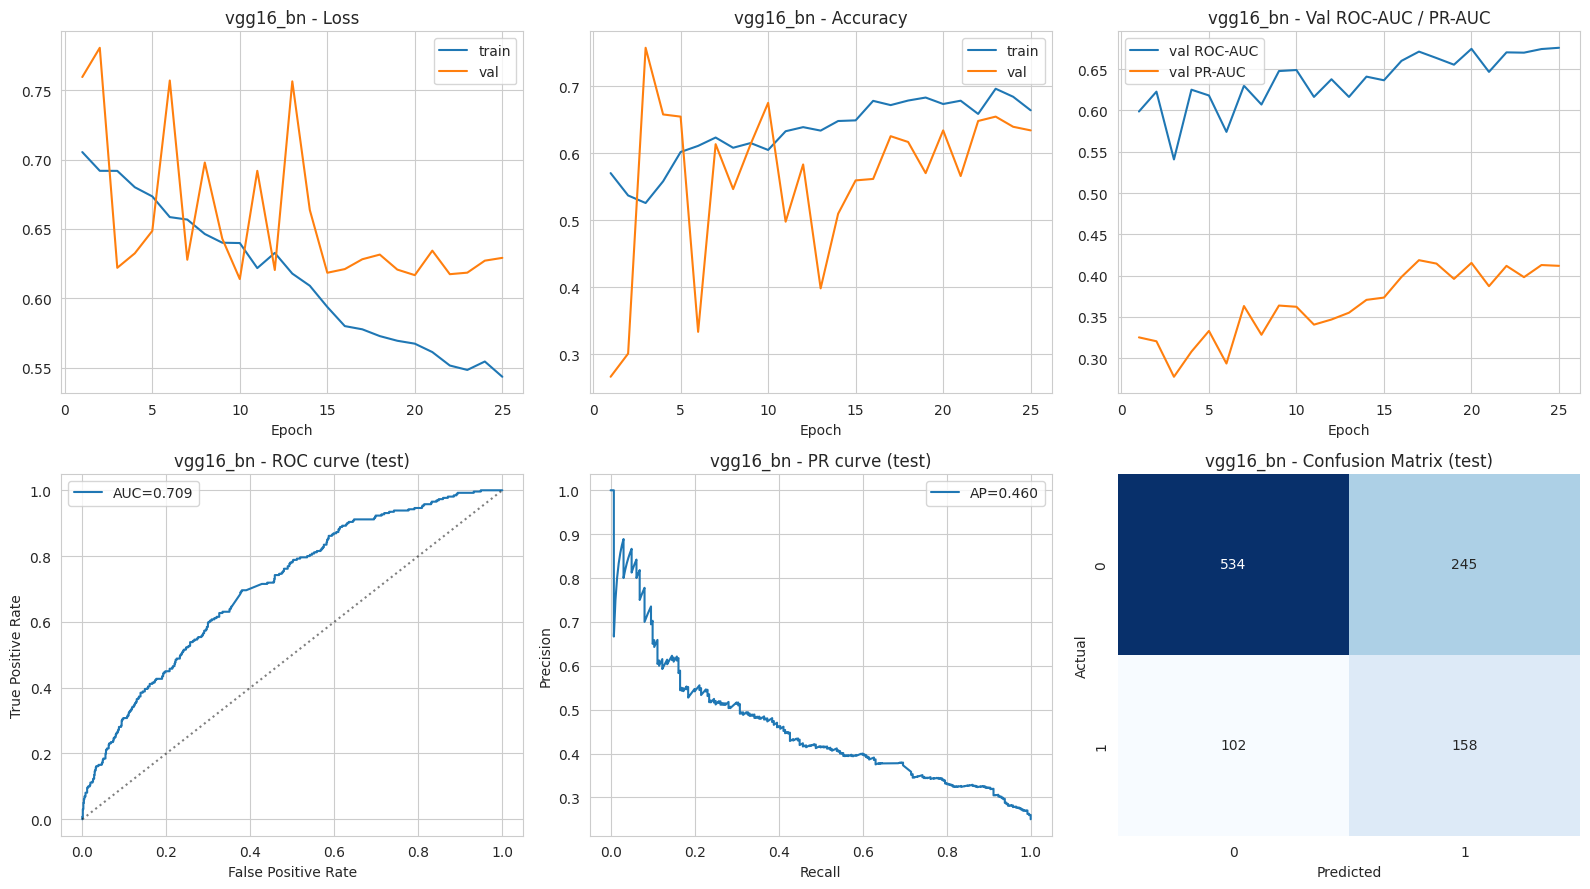

Saved /kaggle/working/figures/per_model/vgg16_bn_full_report.png

vgg16_bn test metrics:
                    vgg16_bn
loss                  0.6228
accuracy              0.6660
precision             0.3921
recall_sensitivity    0.6077
f1                    0.4766
roc_auc               0.7085
pr_auc                0.4602
brier                 0.2149
ece                   0.1973
specificity           0.6855


In [15]:
vgg16_bn_model, vgg16_bn_history, vgg16_bn_test_metrics, vgg16_bn_test_preds = train_model(
   "vgg16_bn", train_loader, val_loader, test_loader
)

plot_model_report("vgg16_bn", vgg16_bn_history, vgg16_bn_test_metrics, vgg16_bn_test_preds)

## Cross-model comparison + voting ensemble

Found trained results for: ['resnet50', 'densenet121', 'efficientnet_b0', 'vgg16_bn']


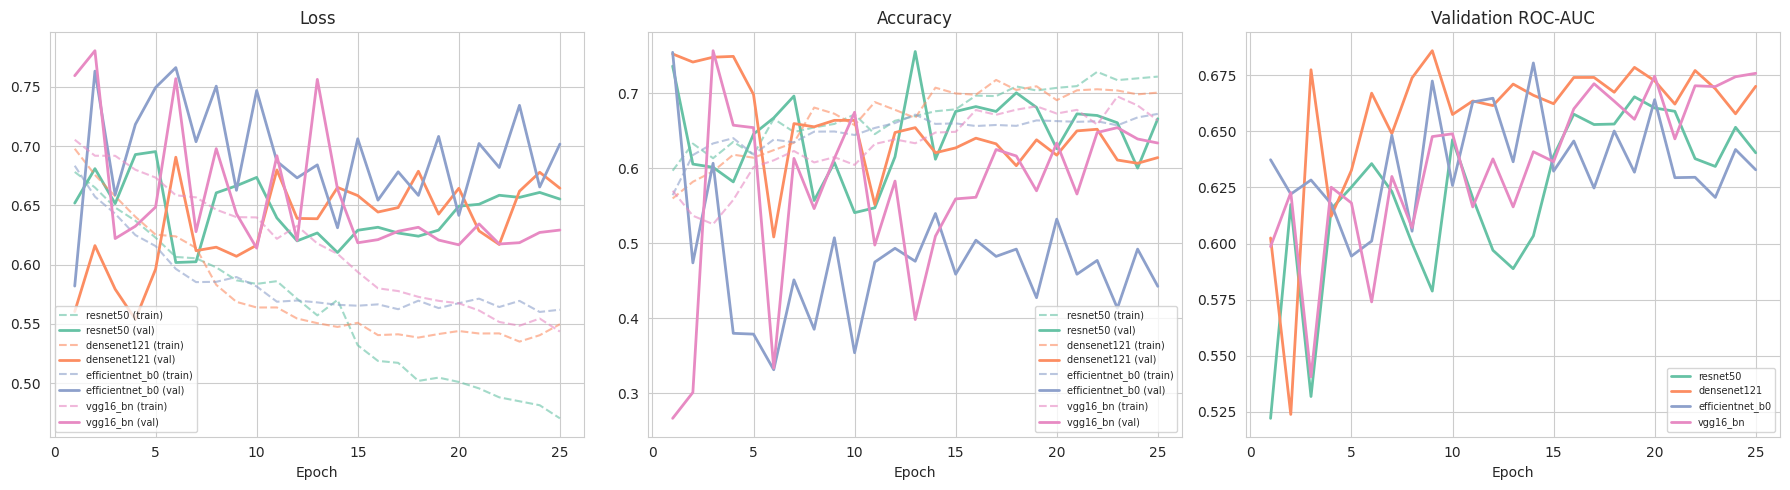


=== Final metrics: individual models + ensembles ===
                 accuracy  precision  recall_sensitivity  specificity      f1  \
resnet50           0.6833     0.3945              0.4962       0.7458  0.4395   
densenet121        0.6747     0.3974              0.5808       0.7060  0.4719   
efficientnet_b0    0.5496     0.3333              0.8000       0.4660  0.4706   
vgg16_bn           0.6660     0.3921              0.6077       0.6855  0.4766   
hard_vote          0.6487     0.3804              0.6423       0.6508  0.4778   
soft_vote          0.6968     0.4259              0.6077       0.7266  0.5008   

                 roc_auc  pr_auc   brier     ece  
resnet50          0.6860  0.4401  0.2095  0.1755  
densenet121       0.7062  0.4469  0.2062  0.1728  
efficientnet_b0   0.6987  0.4412  0.2230  0.2223  
vgg16_bn          0.7085  0.4602  0.2149  0.1973  
hard_vote         0.6948  0.3911  0.2579  0.2267  
soft_vote         0.7198  0.4841  0.2021  0.1794  


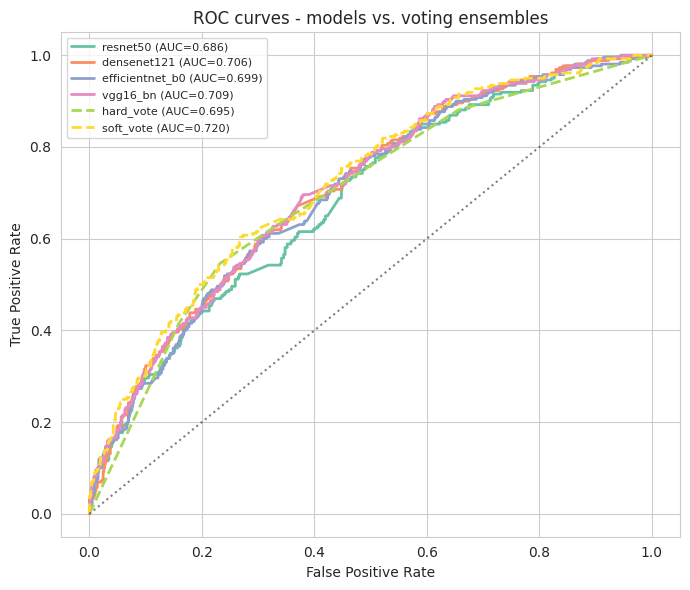

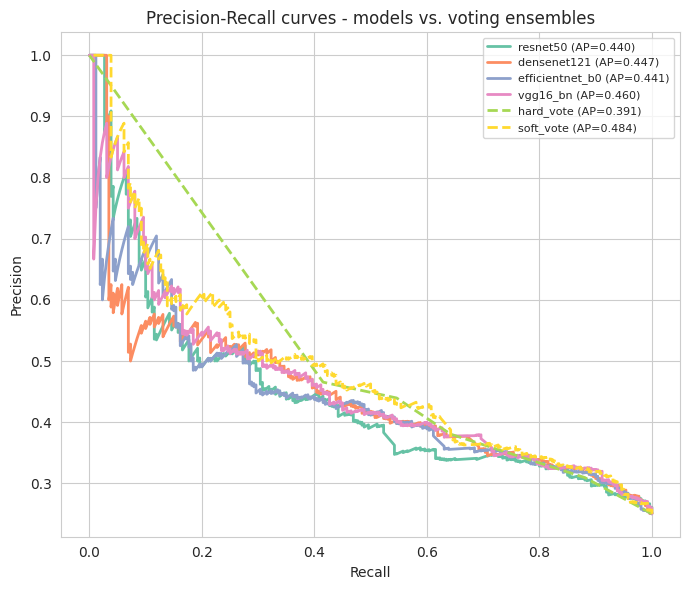

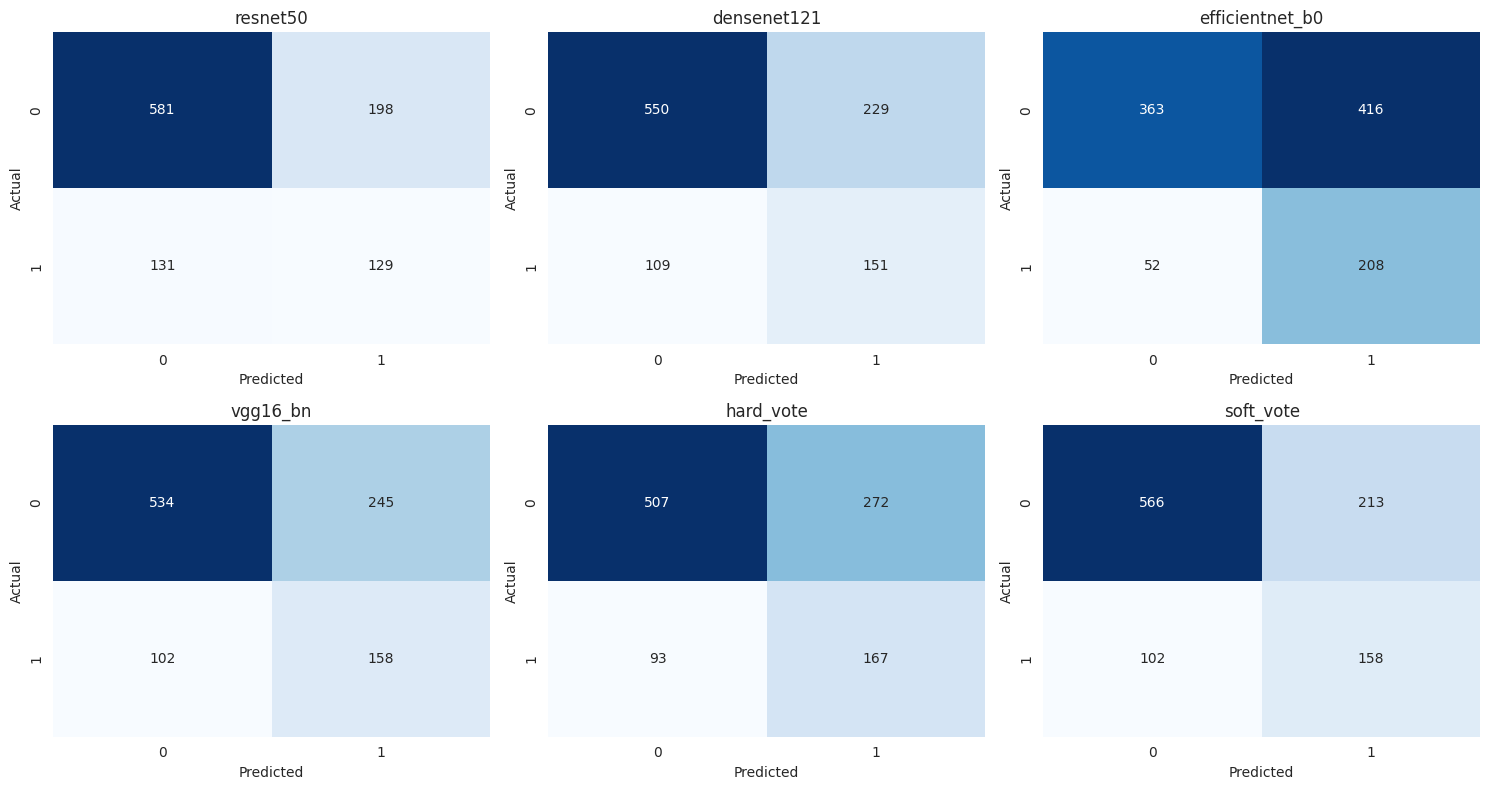

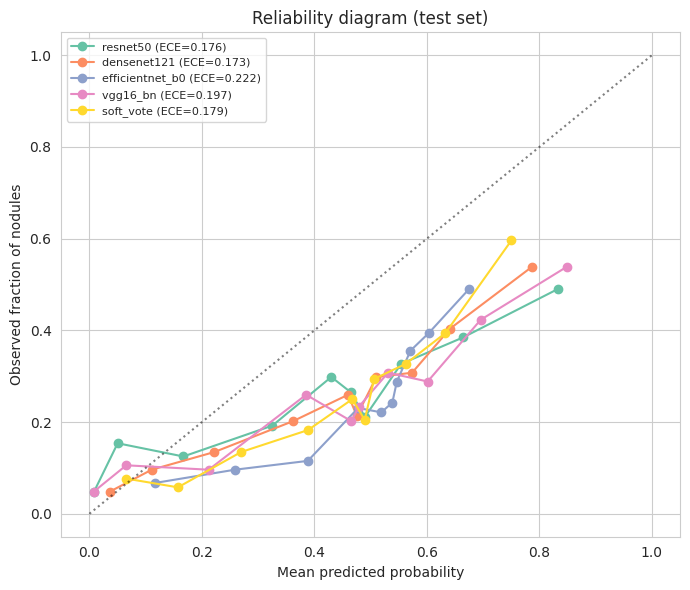

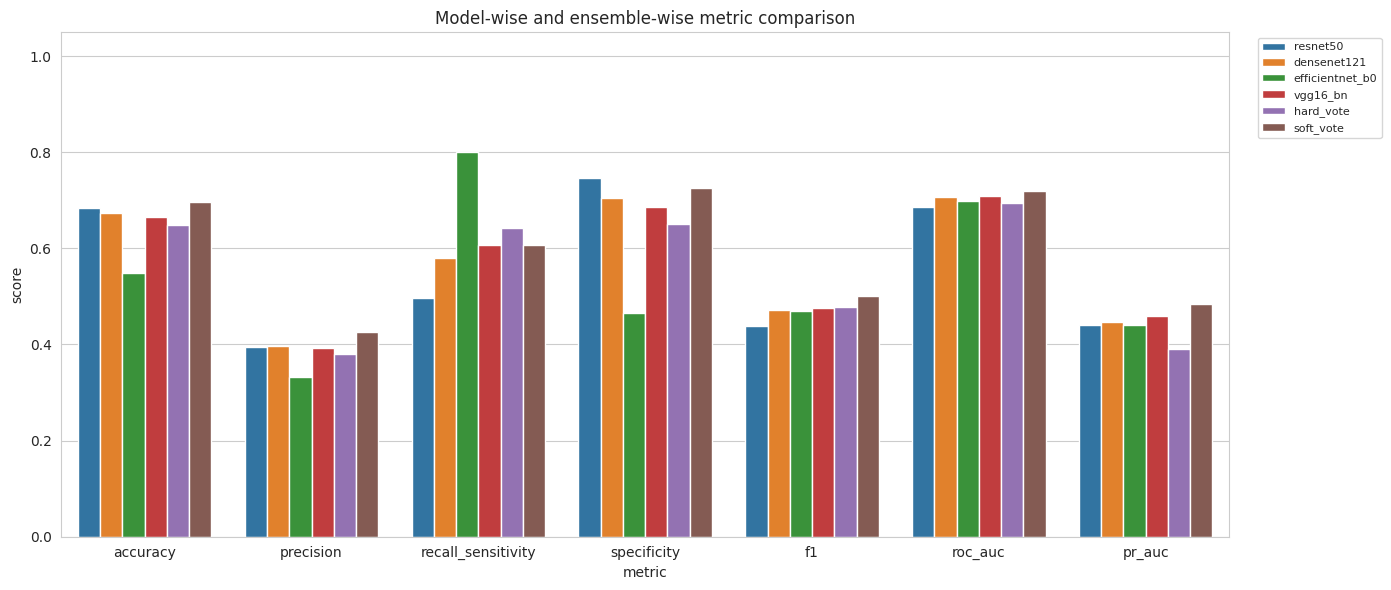


All comparison figures saved to /kaggle/working/figures/comparison


In [16]:
import glob

ALL_POSSIBLE_MODELS = ["resnet50", "densenet121", "efficientnet_b0", "vgg16_bn"]

# Detect which models actually have saved results
trained_models = [
   name for name in ALL_POSSIBLE_MODELS
   if os.path.exists(f"{OUT_DIR}/{name}_history.csv")
   and os.path.exists(f"{OUT_DIR}/{name}_test_predictions.csv")
]
print(f"Found trained results for: {trained_models}")

if len(trained_models) < 2:
   print("Need at least 2 trained models to compare/ensemble. Run more of Blocks 2-5 first.")
else:
   COMPARE_FIG_DIR = "/kaggle/working/figures/comparison"
   os.makedirs(COMPARE_FIG_DIR, exist_ok=True)
   palette = sns.color_palette("Set2", len(trained_models) + 2)

   # -----------------------------------------------------------------
   # 1. Overlaid training curves (loss / accuracy / val ROC-AUC)
   # -----------------------------------------------------------------
   histories = {name: pd.read_csv(f"{OUT_DIR}/{name}_history.csv") for name in trained_models}

   fig, axes = plt.subplots(1, 3, figsize=(18, 5))
   plot_specs = [("train_loss", "val_loss", "Loss"), ("train_acc", "val_acc", "Accuracy"),
                 (None, "val_roc_auc", "Validation ROC-AUC")]
   for ax, (train_col, val_col, title) in zip(axes, plot_specs):
       for i, (name, hist) in enumerate(histories.items()):
           if train_col:
               ax.plot(hist["epoch"], hist[train_col], "--", color=palette[i], alpha=0.6, label=f"{name} (train)")
           ax.plot(hist["epoch"], hist[val_col], "-", color=palette[i], linewidth=2,
                    label=f"{name} (val)" if train_col else name)
       ax.set_title(title)
       ax.set_xlabel("Epoch")
       ax.legend(fontsize=7)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/training_curves_all_models.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 2. Load predictions, build hard/soft voting ensembles
   # -----------------------------------------------------------------
   preds = {name: pd.read_csv(f"{OUT_DIR}/{name}_test_predictions.csv").set_index("filename")
             for name in trained_models}


   base = preds[trained_models[0]][["label"]].copy()
   for name in trained_models:
       base[f"{name}_prob"] = preds[name]["prob"]
       base[f"{name}_pred"] = preds[name]["pred"]

   pred_cols = [f"{name}_pred" for name in trained_models]
   base["hard_vote_prob"] = base[pred_cols].mean(axis=1)
   base["hard_vote_pred"] = (base["hard_vote_prob"] >= 0.5).astype(int)   # 2-2 tie -> positive (favours sensitivity)

   prob_cols = [f"{name}_prob" for name in trained_models]
   base["soft_vote_prob"] = base[prob_cols].mean(axis=1)
   base["soft_vote_pred"] = (base["soft_vote_prob"] >= 0.5).astype(int)

   base.to_csv(f"{OUT_DIR}/ensemble_predictions.csv")
   all_variants = trained_models + ["hard_vote", "soft_vote"]

   # -----------------------------------------------------------------
   # 3. Metrics table for all models + both ensembles
   # -----------------------------------------------------------------
   results = {}
   for name in all_variants:
       y_true, y_pred, y_prob = base["label"], base[f"{name}_pred"], base[f"{name}_prob"]
       tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
       results[name] = {
           "accuracy": accuracy_score(y_true, y_pred),
           "precision": precision_score(y_true, y_pred, zero_division=0),
           "recall_sensitivity": recall_score(y_true, y_pred, zero_division=0),
           "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
           "f1": f1_score(y_true, y_pred, zero_division=0),
           "roc_auc": roc_auc_score(y_true, y_prob),
           "pr_auc": average_precision_score(y_true, y_prob),
           "brier": brier_score_loss(y_true, y_prob),
           "ece": expected_calibration_error(y_true, y_prob),
       }
   metrics_df = pd.DataFrame(results).T
   metrics_df.to_csv(f"{OUT_DIR}/final_metrics_all_models_and_ensembles.csv")
   print("\n=== Final metrics: individual models + ensembles ===")
   print(metrics_df.round(4))

   # -----------------------------------------------------------------
   # 4. Overlaid ROC curves
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       fpr, tpr, _ = roc_curve(base["label"], base[f"{name}_prob"])
       auc_val = roc_auc_score(base["label"], base[f"{name}_prob"])
       style = "--" if "vote" in name else "-"
       plt.plot(fpr, tpr, style, color=palette[i], linewidth=2, label=f"{name} (AUC={auc_val:.3f})")
   plt.plot([0, 1], [0, 1], "k:", alpha=0.5)
   plt.xlabel("False Positive Rate")
   plt.ylabel("True Positive Rate")
   plt.title("ROC curves - models vs. voting ensembles")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/roc_curves_comparison.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 5. Overlaid PR curves
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       precision, recall, _ = precision_recall_curve(base["label"], base[f"{name}_prob"])
       ap = average_precision_score(base["label"], base[f"{name}_prob"])
       style = "--" if "vote" in name else "-"
       plt.plot(recall, precision, style, color=palette[i], linewidth=2, label=f"{name} (AP={ap:.3f})")
   plt.xlabel("Recall")
   plt.ylabel("Precision")
   plt.title("Precision-Recall curves - models vs. voting ensembles")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/pr_curves_comparison.png", dpi=150)
   plt.show()


   # -----------------------------------------------------------------
   # 6. Confusion matrix grid
   # -----------------------------------------------------------------
   n = len(all_variants)
   ncols = 3
   nrows = (n + ncols - 1) // ncols
   fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
   axes = axes.ravel() if n > 1 else [axes]
   for ax, name in zip(axes, all_variants):
       cm = confusion_matrix(base["label"], base[f"{name}_pred"])
       sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
       ax.set_title(name)
       ax.set_xlabel("Predicted")
       ax.set_ylabel("Actual")
   for ax in axes[n:]:
       ax.axis("off")
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/confusion_matrices_grid.png", dpi=150)
   plt.show()


   # -----------------------------------------------------------------
   # 7. Reliability diagram (calibration)
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       if name == "hard_vote":          # vote fractions take only 5 values; not a calibrated probability
           continue
       frac_pos, mean_pred = calibration_curve(base["label"], base[f"{name}_prob"], n_bins=10, strategy="quantile")
       plt.plot(mean_pred, frac_pos, "o-", color=palette[i], label=f"{name} (ECE={results[name]['ece']:.3f})")
   plt.plot([0, 1], [0, 1], "k:", alpha=0.5)
   plt.xlabel("Mean predicted probability")
   plt.ylabel("Observed fraction of nodules")
   plt.title("Reliability diagram (test set)")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/calibration_reliability.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 8. Metric bar chart
   # -----------------------------------------------------------------
   plot_metrics = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]
   plot_df = metrics_df[plot_metrics].reset_index().rename(columns={"index": "model"})
   melted = plot_df.melt(id_vars="model", var_name="metric", value_name="score")

   plt.figure(figsize=(14, 6))
   sns.barplot(data=melted, x="metric", y="score", hue="model")
   plt.title("Model-wise and ensemble-wise metric comparison")
   plt.ylim(0, 1.05)
   plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/metric_comparison_bar_chart.png", dpi=150)
   plt.show()

   print(f"\nAll comparison figures saved to {COMPARE_FIG_DIR}")

In [17]:
!pip install grad-cam --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Grad-CAM explainability

Running Grad-CAM for: ['resnet50', 'densenet121', 'efficientnet_b0', 'vgg16_bn']


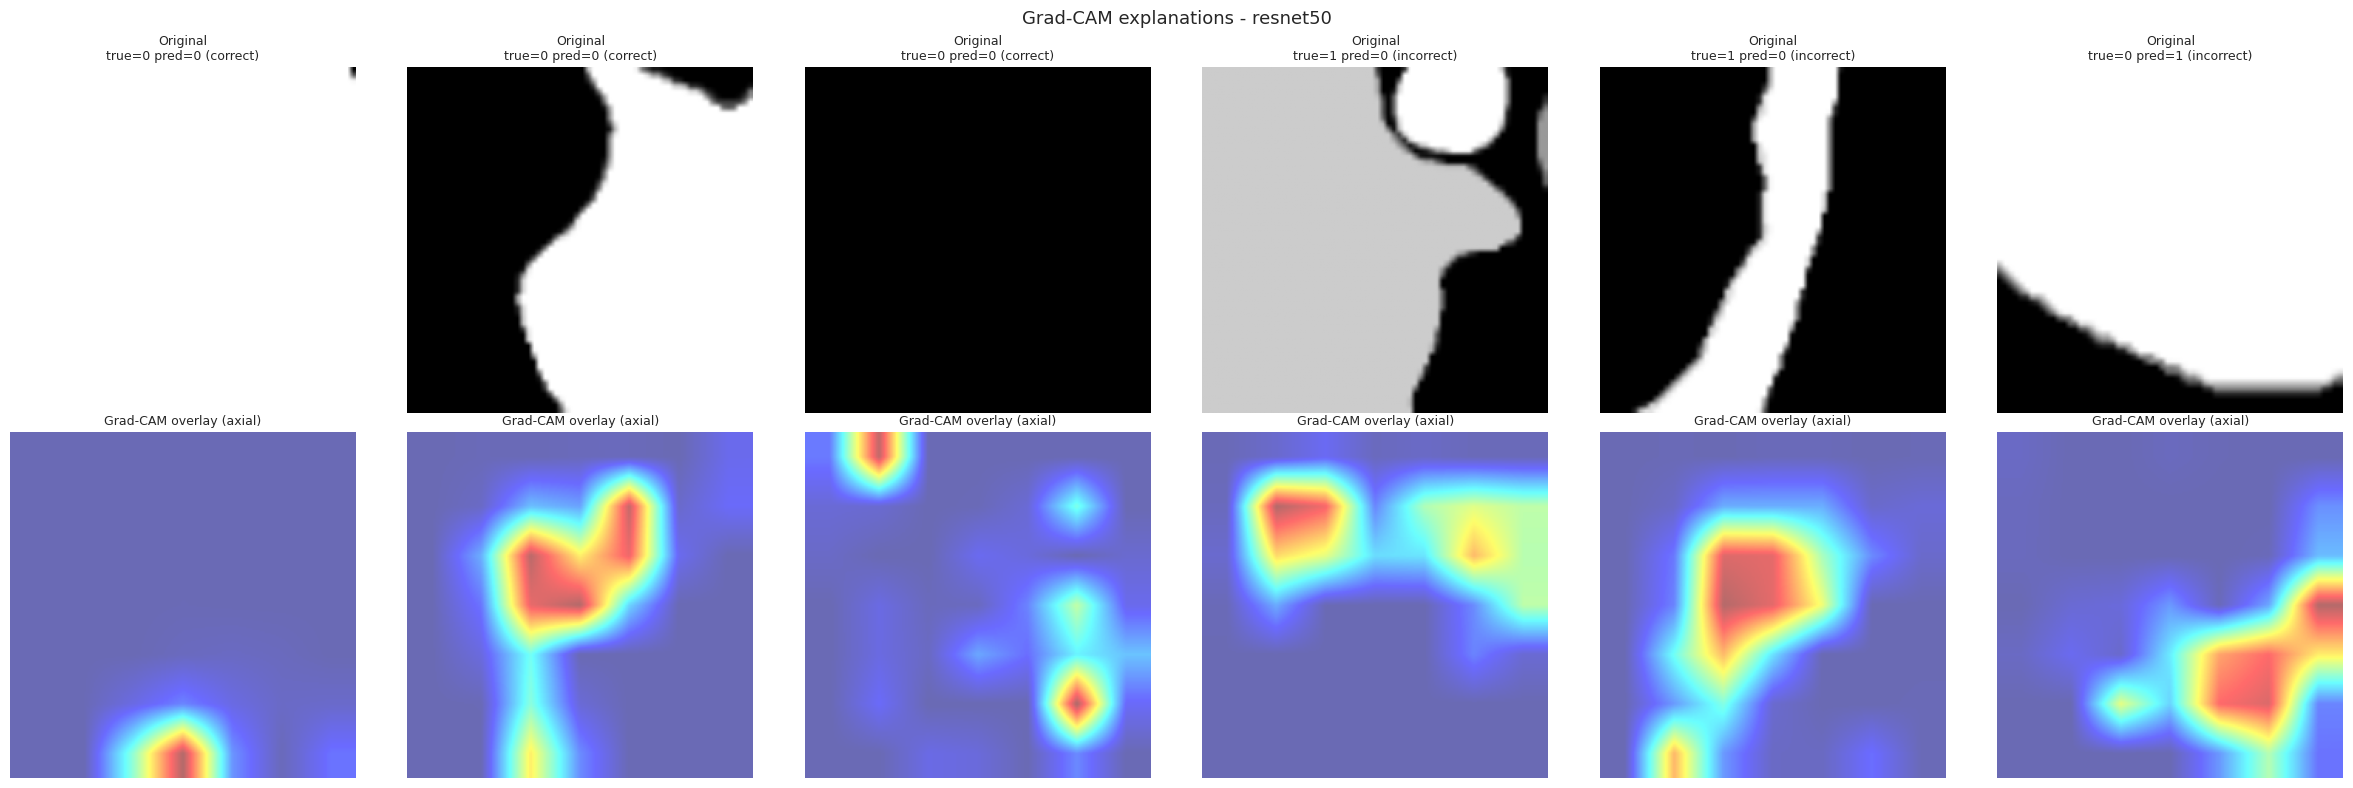

Saved /kaggle/working/figures/gradcam/resnet50_gradcam.png


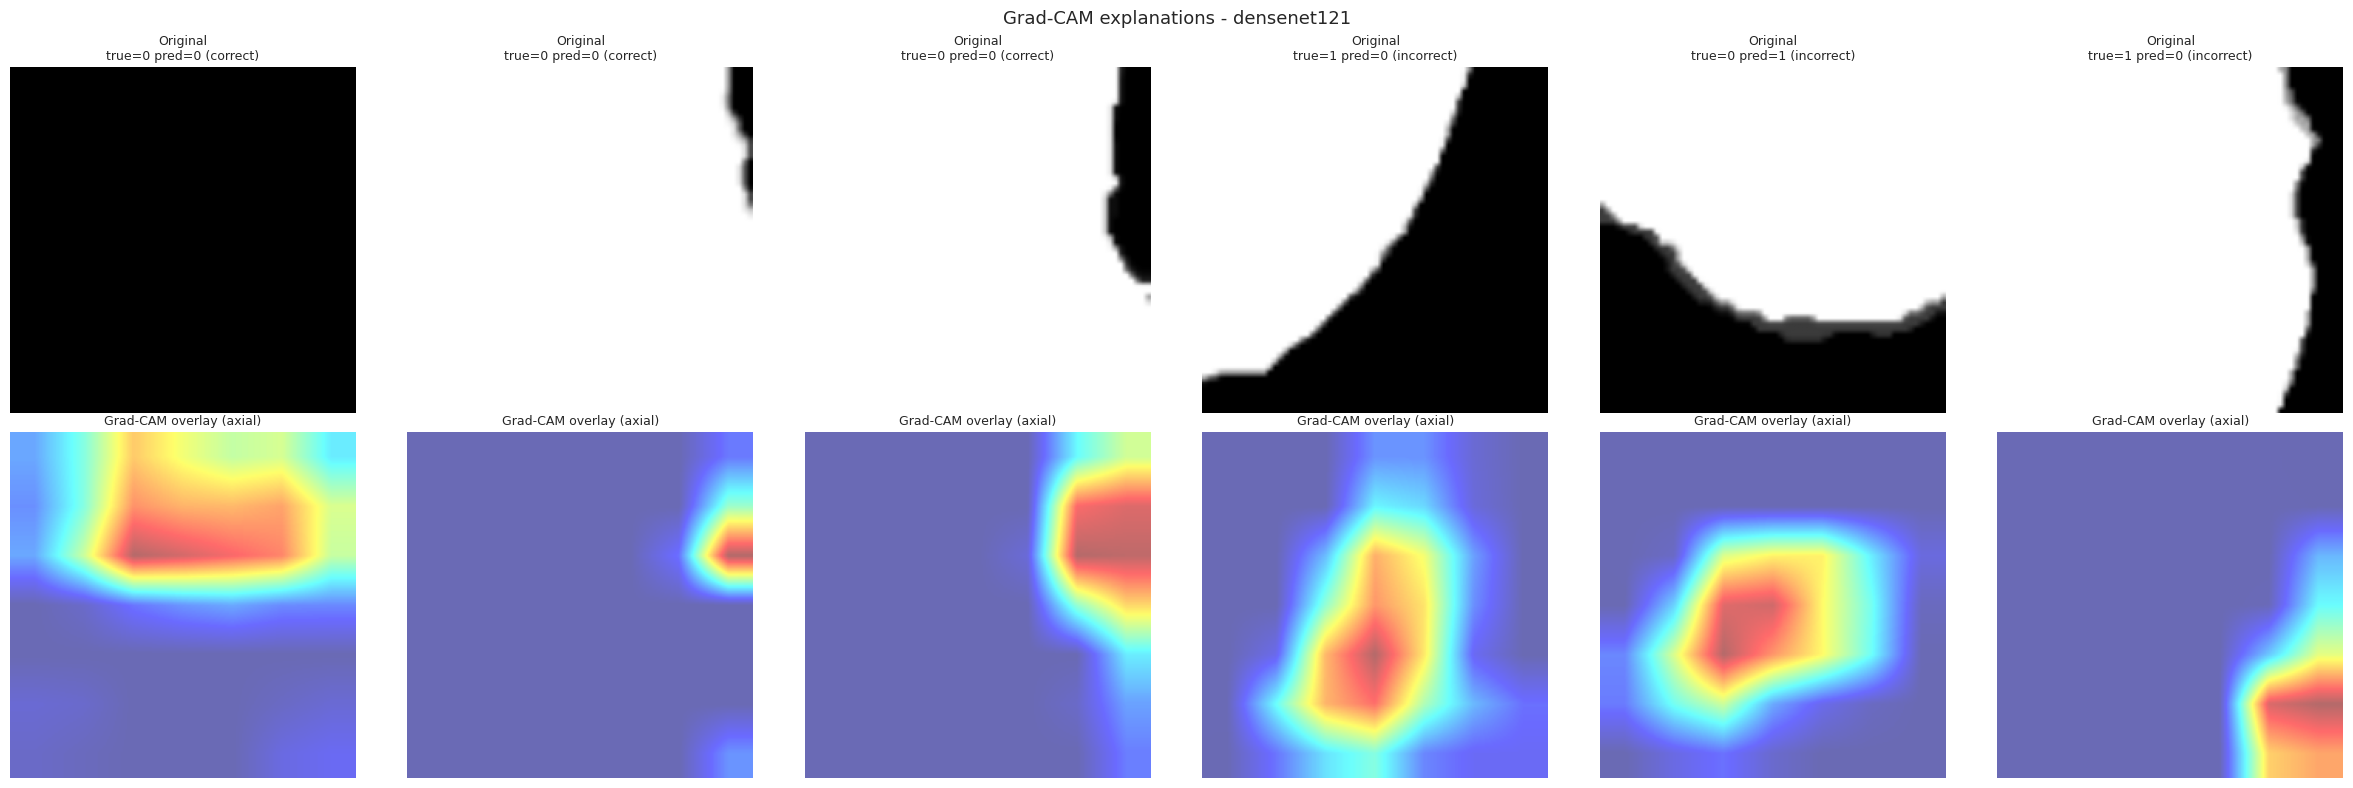

Saved /kaggle/working/figures/gradcam/densenet121_gradcam.png


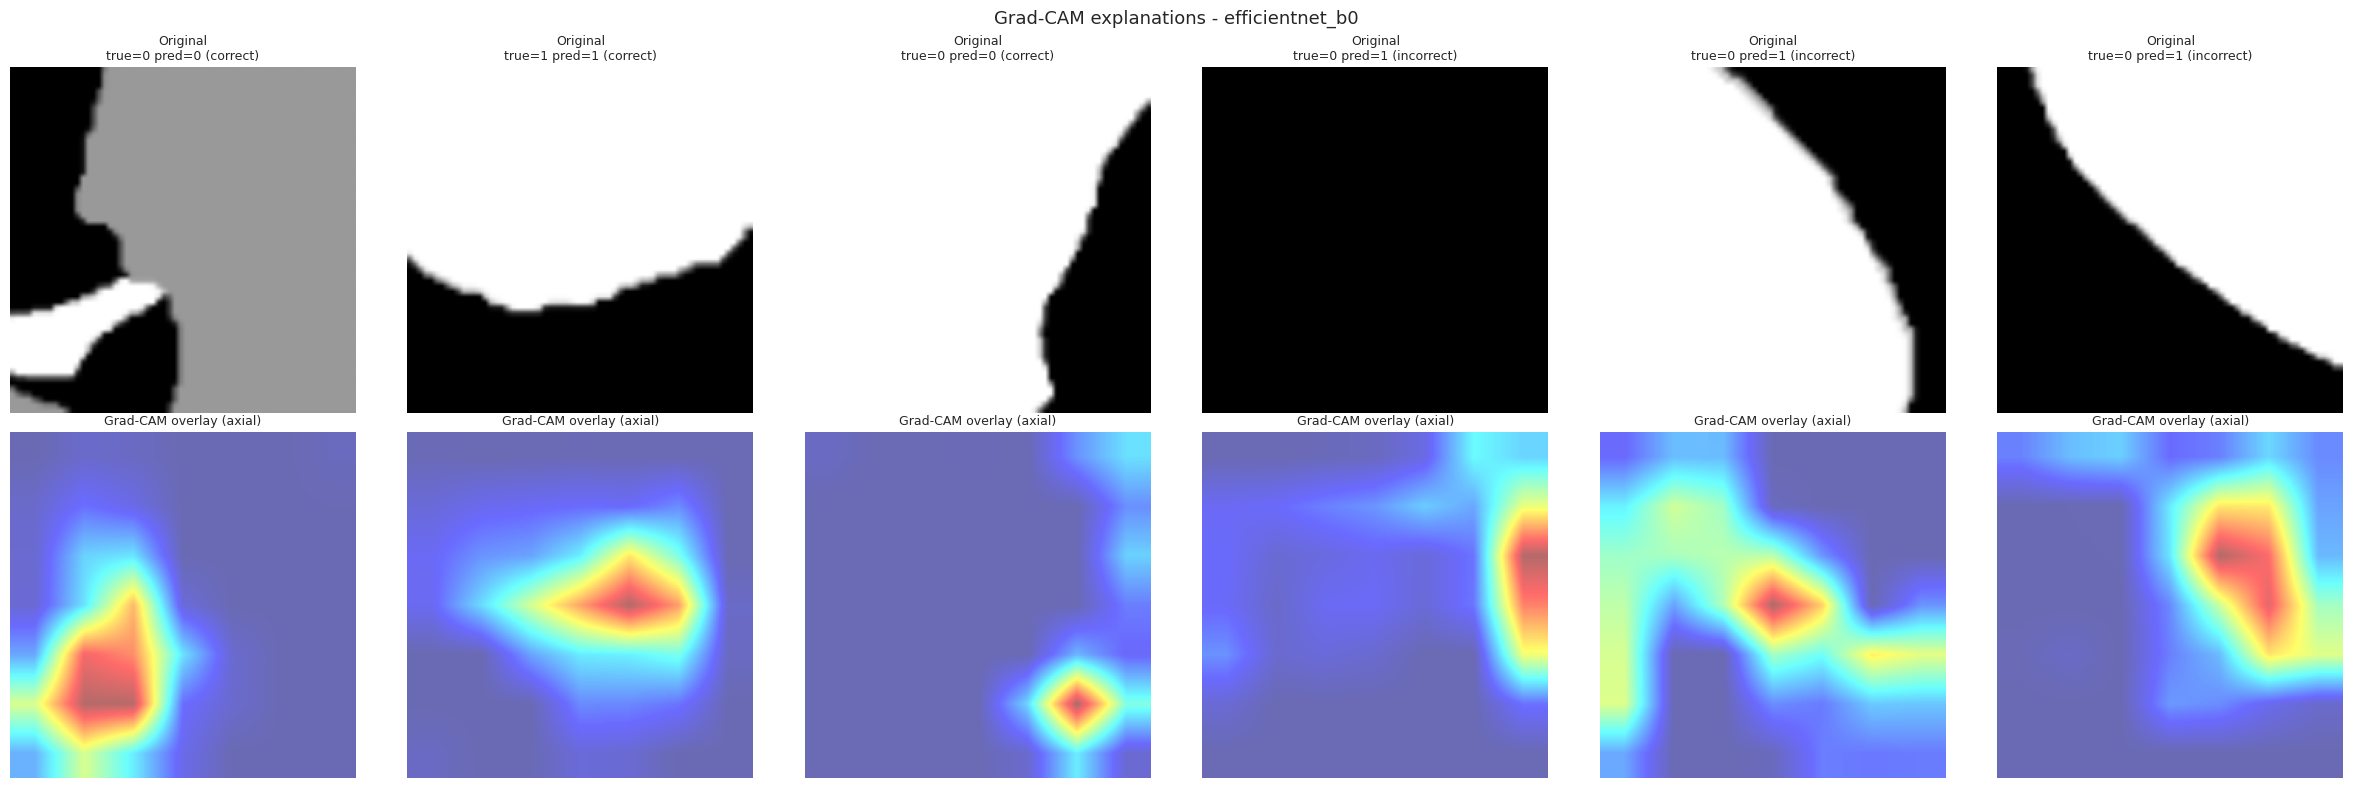

Saved /kaggle/working/figures/gradcam/efficientnet_b0_gradcam.png


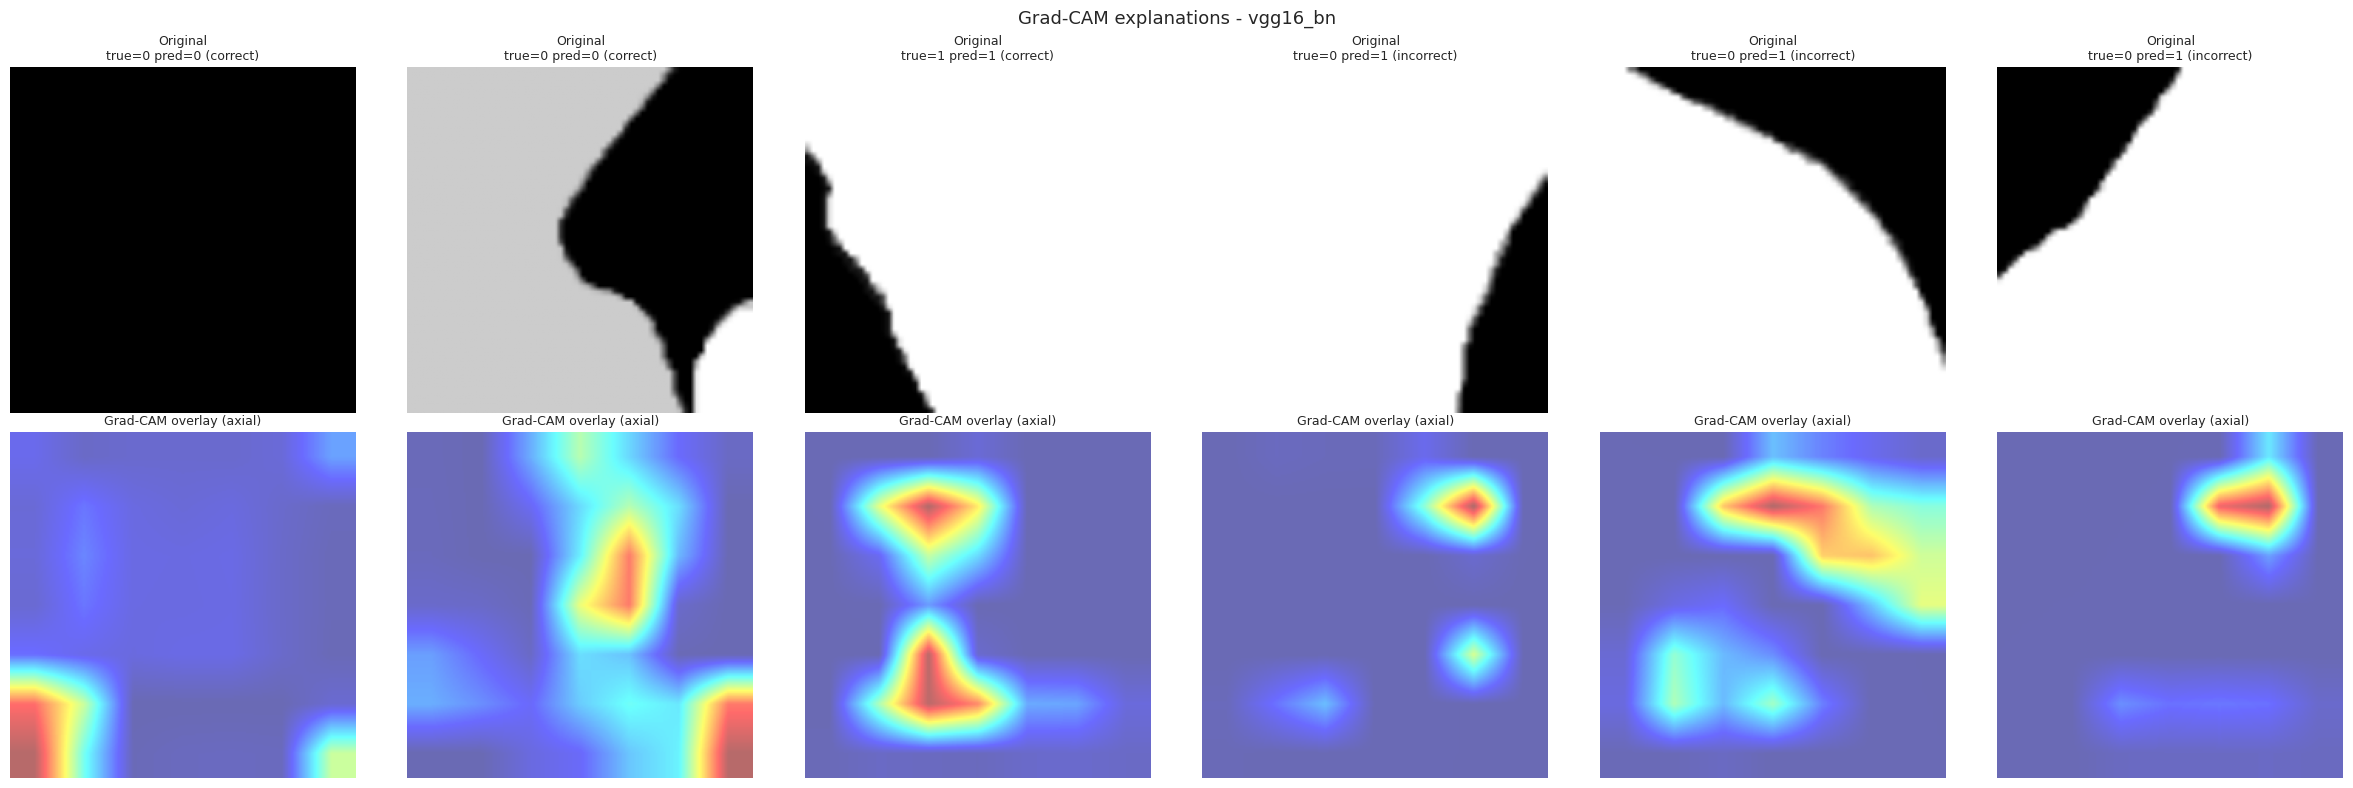

Saved /kaggle/working/figures/gradcam/vgg16_bn_gradcam.png


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


GRADCAM_FIG_DIR = "/kaggle/working/figures/gradcam"
os.makedirs(GRADCAM_FIG_DIR, exist_ok=True)


# The last convolutional layer to target for each architecture -
# Grad-CAM needs the last conv block's feature maps.
TARGET_LAYERS = {
   "resnet50": lambda m: [m.layer4[-1]],
   "densenet121": lambda m: [m.features[-1]],
   "efficientnet_b0": lambda m: [m.features[-1]],
   "vgg16_bn": lambda m: [m.features[-1]],
}


def load_trained_model(model_name):
   """Rebuild the architecture and load its best checkpoint."""
   model = build_model(model_name)
   checkpoint_path = f"{OUT_DIR}/{model_name}_best.pt"
   model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
   model.eval()
   return model

def run_gradcam_for_model(model_name, n_correct=3, n_incorrect=3):
   if not os.path.exists(f"{OUT_DIR}/{model_name}_test_predictions.csv"):
       print(f"No results found for {model_name}, skipping.")
       return

   model = load_trained_model(model_name)
   target_layers = TARGET_LAYERS[model_name](model)
   cam = GradCAM(model=model, target_layers=target_layers)

   preds_df = pd.read_csv(f"{OUT_DIR}/{model_name}_test_predictions.csv")
   correct_df = preds_df[preds_df["label"] == preds_df["pred"]]
   incorrect_df = preds_df[preds_df["label"] != preds_df["pred"]]

   correct_sample = correct_df.sample(min(n_correct, len(correct_df)), random_state=42)
   incorrect_sample = incorrect_df.sample(min(n_incorrect, len(incorrect_df)), random_state=42) \
       if len(incorrect_df) > 0 else incorrect_df

   combined = pd.concat([
       correct_sample.assign(status="correct"),
       incorrect_sample.assign(status="incorrect"),
   ])

   n = len(combined)
   if n == 0:
       print(f"No samples to visualize for {model_name}.")
       return

   fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
   if n == 1:
       axes = axes.reshape(2, 1)

   for col_idx, (_, row) in enumerate(combined.iterrows()):
       crop = torch.from_numpy(np.load(os.path.join(DATA_DIR, row["filename"]))).float()  # (3, H, W) in [0,1]
       input_tensor = to_model_input(crop).unsqueeze(0).to(DEVICE)
       axial = transforms.functional.resize(crop[0:1], [INPUT_SIZE, INPUT_SIZE], antialias=True)[0]
       axial = axial.clamp(0, 1).numpy()

       target_class = int(row["pred"])
       targets = [ClassifierOutputTarget(target_class)]
       grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

       rgb_img = np.stack([axial, axial, axial], axis=-1).astype(np.float32)  # HxWx3 for overlay
       cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

       axes[0, col_idx].imshow(axial, cmap="gray")
       axes[0, col_idx].set_title(f"Original\ntrue={row['label']} pred={row['pred']} ({row['status']})", fontsize=9)
       axes[0, col_idx].axis("off")

       axes[1, col_idx].imshow(cam_overlay)
       axes[1, col_idx].set_title("Grad-CAM overlay (axial)", fontsize=9)
       axes[1, col_idx].axis("off")

   plt.suptitle(f"Grad-CAM explanations - {model_name}", fontsize=13)
   plt.tight_layout()
   save_path = f"{GRADCAM_FIG_DIR}/{model_name}_gradcam.png"
   plt.savefig(save_path, dpi=150)
   plt.show()
   print(f"Saved {save_path}")


# Run for every model that has been trained so far
ALL_POSSIBLE_MODELS = ["resnet50", "densenet121", "efficientnet_b0", "vgg16_bn"]
trained_models = [
   name for name in ALL_POSSIBLE_MODELS
   if os.path.exists(f"{OUT_DIR}/{name}_best.pt")
]
print(f"Running Grad-CAM for: {trained_models}")

for name in trained_models:
   run_gradcam_for_model(name)

## Bundle all figures + result CSVs for download

In [19]:
import shutil


STAGE = "/kaggle/working/_zip_stage"
shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree("/kaggle/working/figures", f"{STAGE}/figures")
shutil.copytree(OUT_DIR, f"{STAGE}/model_results", ignore=shutil.ignore_patterns("*.pt"))
zp = shutil.make_archive("/kaggle/working/phase1_results_bundle", "zip", STAGE)
shutil.rmtree(STAGE)
print(f"Created {zp} ({os.path.getsize(zp) / 1e6:.1f} MB)")

Created /kaggle/working/phase1_results_bundle.zip (3.9 MB)
